In [2]:
import warnings
warnings.filterwarnings('ignore')
import pandas as pd
import numpy as np
import seaborn as sns
from plotly.express import scatter_matrix

In [3]:
df = pd.read_csv("data/winequality-red.csv")

In [4]:
df.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


In [6]:
df.duplicated().any()

True

In [7]:
df.duplicated().sum()

240

* 240 duplicate rows are there

In [8]:
df = df.drop_duplicates()

In [9]:
with pd.option_context('display.precision', 2):
    explore = df.describe().T.style.background_gradient(cmap='Reds')
explore

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1359.000000,8.310596,1.736990,4.600000,7.100000,7.900000,9.200000,15.900000
volatile acidity,1359.000000,0.529478,0.183031,0.120000,0.390000,0.520000,0.640000,1.580000
citric acid,1359.000000,0.272333,0.195537,0.000000,0.090000,0.260000,0.430000,1.000000
residual sugar,1359.000000,2.523400,1.352314,0.900000,1.900000,2.200000,2.600000,15.500000
chlorides,1359.000000,0.088124,0.049377,0.012000,0.070000,0.079000,0.091000,0.611000
free sulfur dioxide,1359.000000,15.893304,10.447270,1.000000,7.000000,14.000000,21.000000,72.000000
total sulfur dioxide,1359.000000,46.825975,33.408946,6.000000,22.000000,38.000000,63.000000,289.000000
density,1359.000000,0.996709,0.001869,0.990070,0.995600,0.996700,0.997820,1.003690
pH,1359.000000,3.309787,0.155036,2.740000,3.210000,3.310000,3.400000,4.010000
sulphates,1359.000000,0.658705,0.170667,0.330000,0.550000,0.620000,0.730000,2.000000


In [10]:
corr = df.corr(numeric_only=True)

corr.style.background_gradient(
    cmap='coolwarm',
    vmin=-1,
    vmax=1
).format('{:.2f}')

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
fixed acidity,1.00,-0.26,0.67,0.11,0.09,-0.14,-0.10,0.67,-0.69,0.19,-0.06,0.12
volatile acidity,-0.26,1.00,-0.55,-0.00,0.06,-0.02,0.07,0.02,0.25,-0.26,-0.20,-0.40
citric acid,0.67,-0.55,1.00,0.14,0.21,-0.05,0.05,0.36,-0.55,0.33,0.11,0.23
residual sugar,0.11,-0.00,0.14,1.00,0.03,0.16,0.20,0.32,-0.08,-0.01,0.06,0.01
chlorides,0.09,0.06,0.21,0.03,1.00,0.00,0.05,0.19,-0.27,0.39,-0.22,-0.13
free sulfur dioxide,-0.14,-0.02,-0.05,0.16,0.00,1.00,0.67,-0.02,0.06,0.05,-0.08,-0.05
total sulfur dioxide,-0.10,0.07,0.05,0.20,0.05,0.67,1.00,0.08,-0.08,0.04,-0.22,-0.18
density,0.67,0.02,0.36,0.32,0.19,-0.02,0.08,1.00,-0.36,0.15,-0.50,-0.18
pH,-0.69,0.25,-0.55,-0.08,-0.27,0.06,-0.08,-0.36,1.00,-0.21,0.21,-0.06
sulphates,0.19,-0.26,0.33,-0.01,0.39,0.05,0.04,0.15,-0.21,1.00,0.09,0.25


In [11]:
ave_qu = df.groupby("quality").mean()
ave_qu

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol
quality,,,,,,,,,,,
3,8.360000,0.884500,0.171000,2.635000,0.122500,11.000000,24.900000,0.997464,3.398000,0.570000,9.955000
4,7.779245,0.693962,0.174151,2.694340,0.090679,12.264151,36.245283,0.996542,3.381509,0.596415,10.265094
5,8.171231,0.578596,0.244523,2.509532,0.093971,17.161179,57.406412,0.997082,3.300815,0.623570,9.888562
6,8.337383,0.496084,0.279364,2.457290,0.085075,15.637383,40.816822,0.996565,3.318000,0.674542,10.658879
7,8.858683,0.403653,0.371856,2.716766,0.076832,13.994012,35.449102,0.996051,3.290060,0.742635,11.491118
8,8.441176,0.427647,0.382941,2.576471,0.068353,13.764706,34.470588,0.995095,3.274118,0.774706,12.158824


<Axes: xlabel='quality'>

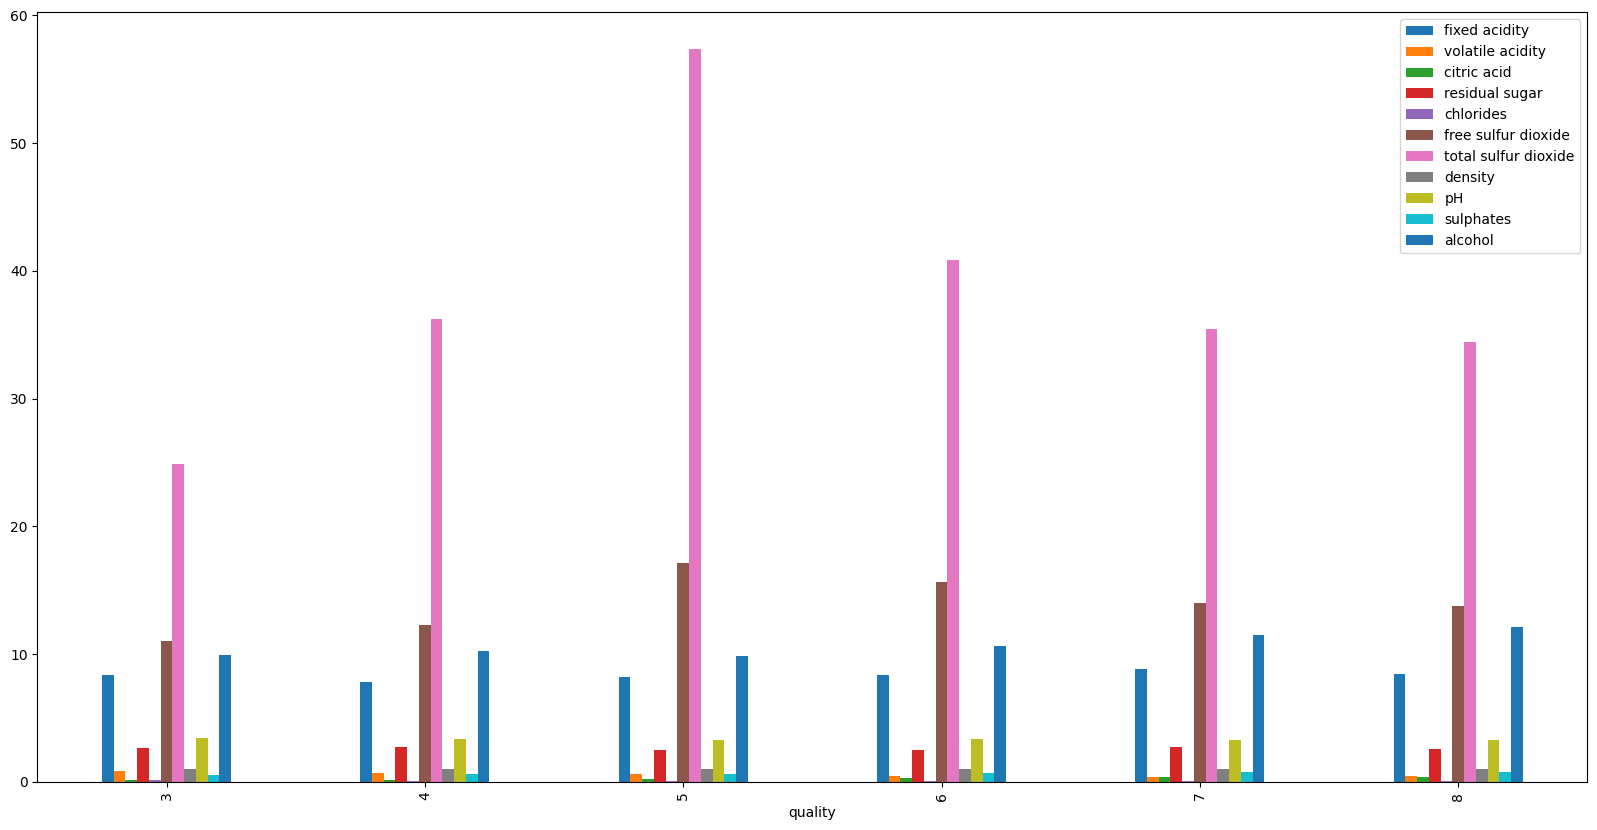

In [12]:
ave_qu.plot(kind="bar",figsize=(20,10))

In [13]:
colors = ['#FC4F4F', '#FFBC80', '#FF9F45', '#F76E11', '#CD104D', '#820000']
quality = [3,4,5,6,7,8]

In [14]:
import plotly

In [15]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go


In [16]:
fig = make_subplots(rows = 1, cols = 2, specs = [[{"type": "pie"}, {"type": "bar"}]])
fig.add_trace(go.Pie(values = df.quality.value_counts(), labels = df.quality.value_counts().index, domain = dict(x=[0, 0.5]), 
                     marker = dict(colors = colors), hole = .3, name=''), row = 1, col = 1)
fig.add_trace(go.Bar(x = df.quality.value_counts().index, y = df.quality.value_counts(), name='', marker = dict(color = quality,
                     colorscale = colors)), row = 1, col = 2)
fig.update_layout(showlegend = False)
fig.show()

In [ ]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats

fig = make_subplots(
    rows=4,
    cols=3,
    subplot_titles=df.columns
)

for j, col in enumerate(df.columns):
    values = df[col].dropna().values

    row = j // 3 + 1
    column = j % 3 + 1

    # Histogram
    fig.add_trace(
        go.Histogram(
            x=values,
            histnorm="probability density",
            marker_color="#f94449",
            showlegend=False
        ),
        row=row,
        col=column
    )

    # KDE curve (only for numeric columns with sufficient variation)
    if len(values) > 1 and np.std(values) > 0:
        kde = stats.gaussian_kde(values)
        x_range = np.linspace(values.min(), values.max(), 200)

        fig.add_trace(
            go.Scatter(
                x=x_range,
                y=kde(x_range),
                mode="lines",
                line=dict(color="#de0a26", width=2),
                showlegend=False
            ),
            row=row,
            col=column
        )

fig.update_layout(
    height=1200,
    showlegend=False,
    margin={"l": 20, "r": 20, "t": 50, "b": 20}
)

fig.show()

* There are 5 types of quality in DataSet - 3 to 8
* The Best quality 8 and worst quality is 3. 
* The elements highest effect on the quality of wine:
1. Total sulfur dioxide
2. Free sulfur dioxide
3. Alcohol